# C=5 MLP vs. LEAR: lokaler Vergleich

Dieses Notebook verwendet ausschließlich bereits vorhandene lokale Markt-, Last-, DWD- und Forecast-Dateien. Es lädt keine Daten herunter, verändert keine Pipeline-Dateien und sendet nichts an Energy Arena.

Die Performance wird über einen kurzen rollierenden Backtest auf den jüngsten Tagen mit vollständigen Istpreisen gemessen. MLP und gespeicherter C=5-LEAR-Forecast werden dabei auf exakt denselben Tagen und Istwerten verglichen. Für morgen werden zusätzlich die beiden Prognosekurven verglichen; da der Istpreis für diesen Liefertag noch nicht vorliegt, ist das **kein Performancevergleich**.

In [1]:
from datetime import date, timedelta
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "run_pipeline.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Repository root not found; open this notebook from the EPF_Pipe workspace.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from experiment_manifest import get_lear_run
from pipeline.delivery_index import read_forecast_csv
from pipeline.mlp.mlp import MLPConfig, rolling_mlp_forecast
from pipeline.operational.config import load_operational_config
from pipeline.operational.runner import (
    _assemble_matrices,
    _load_weather_features,
    _read_cache_only,
)

# Change these values if you want another forecast date or backtest length.
TARGET_DATE = date(2026, 11, 4)
BACKTEST_DAYS = 14
TRAIN_DAYS = 56
config = load_operational_config(ROOT)
lear_run = get_lear_run("dwd_d56_c5_fundamental")
mlp_config = MLPConfig(
    train_days=TRAIN_DAYS,
    max_epochs=100,
    patience=15,
)
print(f"Repository: {ROOT}")
print(f"Target: {TARGET_DATE}; backtest window: up to {BACKTEST_DAYS} realized days")

Repository: c:\Users\tobia\OneDrive\Desktop\EPF_Pipe
Target: 2026-11-04; backtest window: up to 14 realized days


In [2]:
# Read-only local caches. Extra history covers the 56-day model window,
# the backtest days, and the price lag feature construction.
first_required_date = TARGET_DATE - timedelta(days=TRAIN_DAYS + BACKTEST_DAYS + 10)
price_path = config.entsoe_price_cache_dir / "prices_da.csv"
load_path = config.entsoe_load_cache_dir / "load_forecast.csv"
for required_path in (price_path, load_path):
    if not required_path.is_file():
        raise FileNotFoundError(f"Required local cache is missing: {required_path}")

prices = _read_cache_only(
    price_path, first_required_date, TARGET_DATE, config.timezone,
    allow_incomplete=True,
)
load = _read_cache_only(
    load_path, first_required_date, TARGET_DATE, config.timezone,
    allow_incomplete=True,
)
weather_c5 = _load_weather_features(
    config, 5, first_required_date, TARGET_DATE
)
X, Y = _assemble_matrices(
    config,
    lear_run,
    prices=prices,
    exaa=None,
    load=load,
    weather={5: weather_c5},
    first_feature_date=first_required_date,
    target_date=TARGET_DATE,
)

lear_forecast_path = lear_run.output_dir(config.results_root) / "forecast.csv"
if not lear_forecast_path.is_file():
    raise FileNotFoundError(
        f"Saved C=5 LEAR forecast not found: {lear_forecast_path}. "
        "Run the existing C=5 LEAR forecast first; this notebook will not generate it."
    )
lear_forecasts = read_forecast_csv(
    lear_forecast_path,
    required_columns=("y_pred", "y_true"),
    require_complete_days=True,
)
print(f"Features: {X.shape}; daily targets: {Y.shape}")
print(f"Cached LEAR forecast: {lear_forecast_path}")

dwd_d56_c5_fundamental: incomplete feature days detected=17; operational missing-input policy will be applied
Features: (81, 1473); daily targets: (81, 96)
Cached LEAR forecast: C:\Users\tobia\OneDrive\Desktop\EPF_Pipe\data\operational\results\lear_op_results\dwd\d56\c5\fundamental\forecast.csv


## Rollierender Backtest

Es werden bis zu 14 jüngste Tage vor `TARGET_DATE` verwendet, für die gespeicherter LEAR-Forecast, Istpreise und vollständige C=5-Eingaben verfügbar sind. Der MLP wird für jeden Tag nur mit vorherigen Daten trainiert. Beide Modelle werden auf denselben Viertelstunden und Istpreisen bewertet.

,MAE,RMSE,Bias
MLP,42.496,53.628,-25.83
LEAR C=5,31.592,55.129,-23.87


,MLP_MAE,LEAR_C5_MAE
delivery_date,,
2026-10-11,43.165,21.135
2026-10-12,47.119,31.002
2026-10-13,36.470,15.336
2026-10-14,26.417,22.969
2026-10-15,16.967,12.483
2026-10-16,35.586,41.708
2026-10-17,50.486,33.137
2026-10-18,47.137,54.062
2026-10-19,59.538,42.303


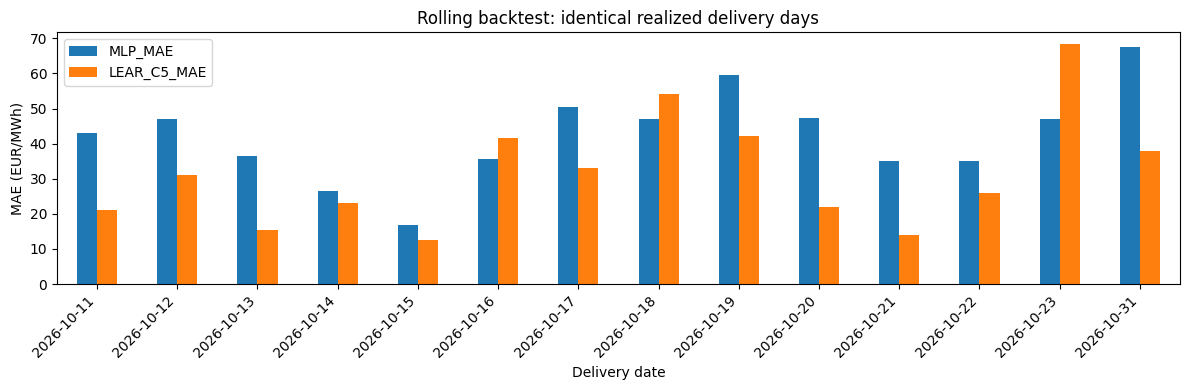

In [3]:
lear_days = lear_forecasts.groupby(level="delivery_date", sort=True)
eligible_days = []
for delivery_day, lear_day in lear_days:
    day = pd.Timestamp(delivery_day).date()
    feature_day = pd.Timestamp(day, tz=config.timezone)
    if day >= TARGET_DATE or not lear_day["y_true"].notna().all():
        continue
    if feature_day not in X.index or feature_day not in Y.index:
        continue
    if not np.isfinite(X.loc[feature_day].to_numpy(dtype=float)).all():
        continue
    if not np.isfinite(Y.loc[feature_day].to_numpy(dtype=float)).all():
        continue
    eligible_days.append(day)

backtest_days = eligible_days[-BACKTEST_DAYS:]
if not backtest_days:
    raise ValueError(
        "No realized dates have complete C=5 inputs and saved LEAR forecasts. "
        "Check the local caches and forecast history."
    )
if len(backtest_days) < BACKTEST_DAYS:
    print(f"Only {len(backtest_days)} eligible realized day(s) found; using all of them.")

mlp_backtest = rolling_mlp_forecast(X, Y, backtest_days, mlp_config)
day_labels = pd.to_datetime(backtest_days)
lear_backtest = lear_forecasts.loc[
    lear_forecasts.index.get_level_values("delivery_date").isin(day_labels)
]
common_index = mlp_backtest.index.intersection(lear_backtest.index)
if len(common_index) != 96 * len(backtest_days):
    raise ValueError("MLP and LEAR backtest indexes do not contain the same full delivery days.")
mlp_backtest = mlp_backtest.loc[common_index]
lear_backtest = lear_backtest.loc[common_index]
actual = mlp_backtest["y_true"].to_numpy(dtype=float)
if not np.isfinite(actual).all() or not np.allclose(
    actual, lear_backtest["y_true"].to_numpy(dtype=float)
):
    raise ValueError("The compared forecasts do not share identical finite actual prices.")

def score(prediction, truth):
    error = np.asarray(prediction, dtype=float) - np.asarray(truth, dtype=float)
    return {
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "Bias": np.mean(error),
    }

overall = pd.DataFrame(
    {
        "MLP": score(mlp_backtest["y_pred"], actual),
        "LEAR C=5": score(lear_backtest["y_pred"], actual),
    }
).T
display(overall.round(3))

daily_rows = []
for day in backtest_days:
    day_key = pd.Timestamp(day)
    mlp_day = mlp_backtest.xs(day_key, level="delivery_date")
    lear_day = lear_backtest.xs(day_key, level="delivery_date")
    truth = mlp_day["y_true"].to_numpy(dtype=float)
    daily_rows.append({
        "delivery_date": day.isoformat(),
        "MLP_MAE": score(mlp_day["y_pred"], truth)["MAE"],
        "LEAR_C5_MAE": score(lear_day["y_pred"], truth)["MAE"],
    })
daily_mae = pd.DataFrame(daily_rows).set_index("delivery_date")
display(daily_mae.round(3))

ax = daily_mae.plot(kind="bar", figsize=(12, 4), ylabel="MAE (EUR/MWh)")
ax.set_title("Rolling backtest: identical realized delivery days")
ax.set_xlabel("Delivery date")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Prognose für den Zieltag

Die folgende Grafik vergleicht nur die MLP- und LEAR-C=5-Prognosewerte für `TARGET_DATE`. Solange die Istpreise für diesen Liefertag fehlen, lässt sich daraus keine Aussage darüber ableiten, welches Modell besser war.

C:\Users\tobia\AppData\Local\Temp\ipykernel_12352\1727023876.py:9: FutureWarning: Indexing a timezone-aware DatetimeIndex with a timezone-naive datetime is deprecated and will raise KeyError in a future version. Use a timezone-aware object instead.
  if target_key not in X.index:


,MTU,MLP_y_pred,LEAR_C5_y_pred,MLP_minus_LEAR
0,1,215.799305,200.697168,15.102137
1,2,220.931742,192.900263,28.031479
2,3,177.170965,185.426296,-8.255330
3,4,182.125028,180.373923,1.751105
4,5,194.221861,178.682942,15.538919


Tomorrow's actual prices are not available; this is a forecast-only comparison.


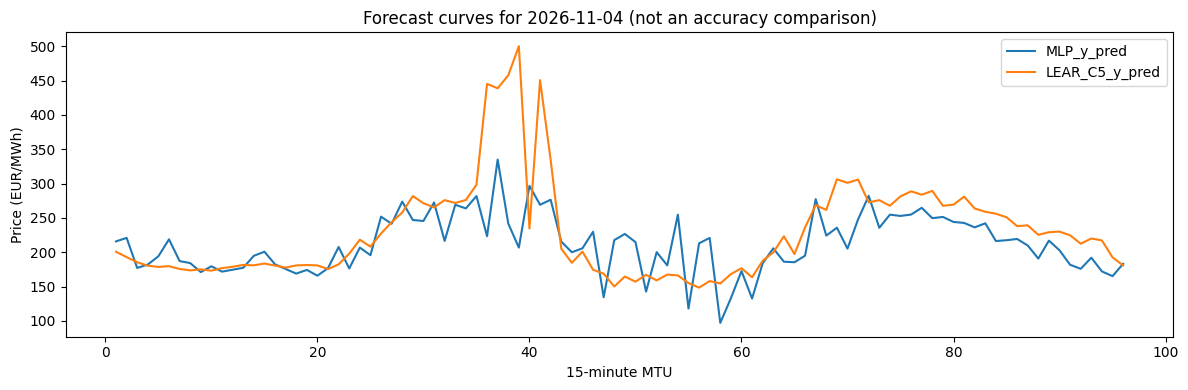

In [4]:
target_key = pd.Timestamp(TARGET_DATE)
try:
    lear_tomorrow = lear_forecasts.xs(target_key, level="delivery_date")
except KeyError as exc:
    raise ValueError(
        f"No saved LEAR C=5 forecast exists for {TARGET_DATE}. "
        "This notebook does not run or submit the operational pipeline."
    ) from exc
if target_key not in X.index:
    raise ValueError(f"C=5 feature row is unavailable for {TARGET_DATE}.")

mlp_tomorrow = rolling_mlp_forecast(X, Y, [TARGET_DATE], mlp_config)
mlp_tomorrow = mlp_tomorrow.xs(target_key, level="delivery_date")
if len(lear_tomorrow) != 96 or not np.isfinite(lear_tomorrow["y_pred"]).all():
    raise ValueError(f"Saved LEAR forecast for {TARGET_DATE} is incomplete.")

tomorrow_comparison = pd.DataFrame({
    "MTU": np.arange(1, 97),
    "MLP_y_pred": mlp_tomorrow["y_pred"].to_numpy(dtype=float),
    "LEAR_C5_y_pred": lear_tomorrow["y_pred"].to_numpy(dtype=float),
})
tomorrow_comparison["MLP_minus_LEAR"] = (
    tomorrow_comparison["MLP_y_pred"] - tomorrow_comparison["LEAR_C5_y_pred"]
)
display(tomorrow_comparison.head())
print("Tomorrow's actual prices are not available; this is a forecast-only comparison.")

ax = tomorrow_comparison.set_index("MTU")[["MLP_y_pred", "LEAR_C5_y_pred"]].plot(
    figsize=(12, 4), ylabel="Price (EUR/MWh)"
)
ax.set_title(f"Forecast curves for {TARGET_DATE} (not an accuracy comparison)")
ax.set_xlabel("15-minute MTU")
plt.tight_layout()
plt.show()